# Receptive fields of example RGCs

Mouse-cam receptive fields (RFs) of 12 RGCs on their EM skeletons. The RFs were estimated in
eyewire2-functional-analysis (`scripts/preprocessing/mc_rfs/fit_mc_rfs.py`) from the responses to the mouse-cam
movie (green and UV channel). Per ROI there is a spatial RF (sRF) and a temporal RF (tRF) per channel, plus a
difference-of-Gaussians (DoG) fit of the sRFs (see `df_eyewire2_roi_level_mc_rf.md` in `data-2p`).

The skeletons are rotated into the 2p frame with the 2p <-> EM registration and placed with the soma at the ROI
position. The RFs and skeletons are corrected with the per-field RF alignment (`rf_alignment.yaml`): the RFs are
moved by the stimulus offset measured with the moving bar, and the skeletons get the EM -> 2p stretch (see
`scripts/analysis/rf_offsets/REPORT.md` in eyewire2-functional-analysis).

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import skeliner as sk
from matplotlib.lines import Line2D

sys.path.append("../utils")

import data_2p_loader as data_loader
import data_io
import rf
from plot import plot_scale_bar
from style import set_rc_params

config = data_io.get_data_config()
data_2p_dir = config["data_2p_dir"]
skel_dir = config["skel_dir"]
for f in (config["mc_rf_file"], config["em_2p_registration_file"], config["rf_alignment_file"]):
    assert os.path.isfile(os.path.join(data_2p_dir, f)), f"{f} not found in {data_2p_dir}"

# Data

In [2]:
df_rois = data_loader.load_df_rois()
df = data_loader.load_df_rois_morph(df_rois=df_rois)
df = df.merge(data_loader.load_df_mc_rfs(), on=data_loader.ROI_KEY_COLS, how='left', validate='one_to_one')
reg = data_loader.load_registration()
rf_alignment = data_loader.load_rf_alignment()

## Example cells

Chosen from the RGCs with a good RF (`qfilt`, DoG r² >= 0.5 in at least one channel, DoG center inside the stimulus)
to cover RF size, polarity and color. Per cell type mostly the cell with the best test correlation of the RF model.

In [3]:
EXAMPLES = [  # (field, roi_id)
    ('GCL0', 23),  # OFF transient alpha: large OFF center
    ('GCL0', 71),  # ON alpha: large ON center
    ('GCL2', 54),  # ON transient medium RF
    ('GCL1', 33),  # OFF transient small RF: small OFF center
    ('GCL4', 65),  # ON transient small RF: small ON center, green about as strong as UV
    ('GCL1', 32),  # F-mini-ON: small ON center
    ('GCL4', 44),  # HD1: small RF
    ('GCL1', 37),  # ON-OFF DS (ventral)
    ('GCL1', 44),  # ON delayed
    ('GCL0', 10),  # bursty suppressed-by-contrast
    ('GCL2', 22),  # M1 ipRGC: sparse arbor
    ('GCL4', 81),  # PixON: ON center in both channels
]

df_ex = pd.concat([df[(df.field == f) & (df.roi_id == r)] for f, r in EXAMPLES])
assert len(df_ex) == len(EXAMPLES)
df_ex[['field', 'roi_id', 'Cell Type', 'mc_rf_best_cc', 'mc_rf_green_dog_r2', 'mc_rf_uv_dog_r2']].round(2)

,field,roi_id,Cell Type,mc_rf_best_cc,mc_rf_green_dog_r2,mc_rf_uv_dog_r2
25,GCL0,23,OFF transient alpha,0.67,0.88,0.99
75,GCL0,71,ON alpha,0.47,0.70,0.99
213,GCL2,54,ON transient medium RF,0.50,0.93,0.99
124,GCL1,33,OFF transient small RF,0.34,0.83,0.95
354,GCL4,65,ON transient small RF,0.22,0.99,0.99
123,GCL1,32,F-mini-ON,0.15,0.74,0.97
333,GCL4,44,HD1,0.27,0.83,0.93
128,GCL1,37,ON-OFF DS - ventral,0.20,0.89,0.92
134,GCL1,44,ON delayed,0.14,0.99,1.00
13,GCL0,10,Bursty suppressed by contrast,0.25,0.68,0.99


### Color opponency of PixON cells

PixON cells were expected to have a color-opponent center. In the mouse-cam RFs, all PixON cells with an RF have the
same polarity in both channels: the green and UV tRFs are strongly correlated (opposite polarities would give a
negative correlation), and the green sRF is weaker than the UV sRF.

In [4]:
d_pix = df[(df['Cell Type'] == 'PixON') & df.qfilt & (df.mc_rf_best_alpha_idx >= 0)].copy()
d_pix['tRF corr (green, UV)'] = [np.corrcoef(g, u)[0, 1] for g, u in zip(d_pix.mc_rf_green_trf, d_pix.mc_rf_uv_trf)]
d_pix['sRF peak green / UV'] = [np.nanmax(np.abs(g)) / np.nanmax(np.abs(u))
                                for g, u in zip(d_pix.mc_rf_green_srf, d_pix.mc_rf_uv_srf)]
d_pix[['field', 'roi_id', 'mc_rf_best_cc', 'mc_rf_green_dog_r2', 'mc_rf_uv_dog_r2', 'tRF corr (green, UV)',
       'sRF peak green / UV']].sort_values('mc_rf_best_cc', ascending=False).round(2)

,field,roi_id,mc_rf_best_cc,mc_rf_green_dog_r2,mc_rf_uv_dog_r2,"tRF corr (green, UV)",sRF peak green / UV
95,GCL1,4,0.26,0.52,0.90,0.91,0.27
43,GCL0,40,0.17,0.34,0.97,0.92,0.26
369,GCL4,81,0.14,0.85,0.96,1.00,0.58
33,GCL0,31,0.14,0.35,0.60,0.96,0.70
155,GCL1,68,0.13,0.51,0.94,0.94,0.74
34,GCL1,61,0.11,0.43,0.98,0.84,0.40
310,GCL4,20,0.10,0.02,0.00,-0.03,1.27
194,GCL2,34,0.04,0.01,0.00,0.80,2.36
193,GCL2,33,0.01,0.12,0.11,0.17,0.99


# Plot

Per cell: green and UV sRF (red = positive, blue = negative; the same color scale for both channels of a cell) with
the skeleton and the 2-sigma ellipses of the DoG center (solid) and surround (dotted; only if the surround is
substantial), and the tRFs scaled by the sRF peak. Ellipses are only drawn for channels with a DoG r² of at least
`R2_FIT`. sRF and tRF are flipped such that the DoG center is positive, i.e. the tRF carries the polarity: positive
just before the response = ON center, negative = OFF center. All sRF panels have the same scale. Right = nasal,
top = dorsal.

Some RFs still sit nasal of their arbor (e.g. the PixON cell in F4): in F0 and F4 the stimulus shift measured with the
moving bar, which is corrected here, is only about half of the shift seen in the mouse-cam RFs.

In [5]:
set_rc_params()

fig_dir = '../figures/calcium_data'
os.makedirs(fig_dir, exist_ok=True)

LIM = 180.  # half-width of the sRF panels (um), the same for all cells so that RF sizes are comparable
R2_FIT = 0.6  # draw the DoG ellipses of a channel only if its DoG r² is at least this
N_PER_ROW = 3

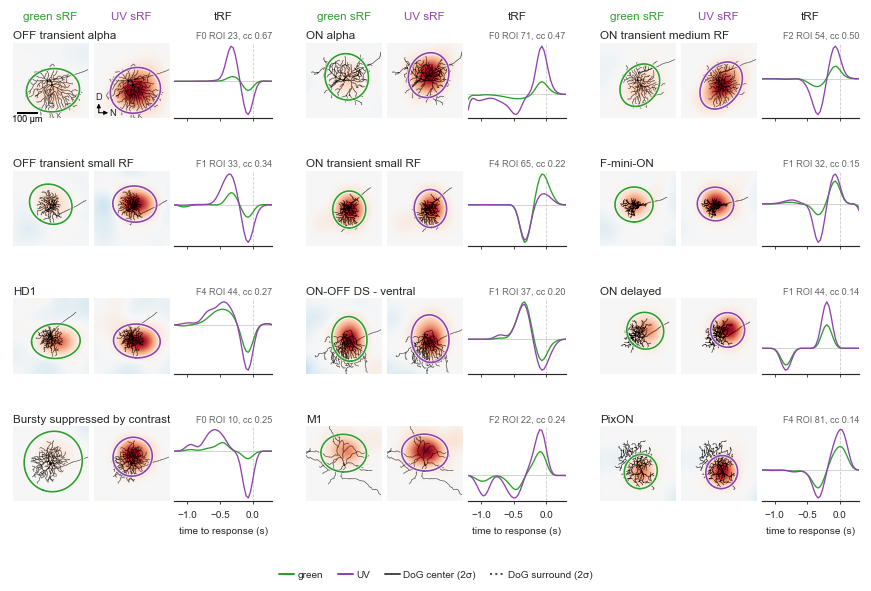

In [6]:
n_rows = int(np.ceil(len(EXAMPLES) / N_PER_ROW))
w_cell = [1, 1, 1.3]
ratios = []
for k in range(N_PER_ROW):
    ratios += ([0.3] if k else []) + w_cell  # spacer between cells

fig = plt.figure(figsize=(7.2, 1.05 * n_rows + 0.75))
gs = fig.add_gridspec(n_rows, len(ratios), width_ratios=ratios, hspace=0.6, wspace=0.08, left=0.01, right=0.99,
                      top=0.91, bottom=0.13)

for i, (_, row) in enumerate(df_ex.iterrows()):
    r_, k = divmod(i, N_PER_ROW)
    c0 = k * (len(w_cell) + 1)
    axs = [fig.add_subplot(gs[r_, c0 + j]) for j in range(len(w_cell))]

    skel = sk.io.load_swc(os.path.join(skel_dir, f"{row['Latest SegID']}.swc"))
    skel = rf.place_skel(skel, reg, row.field, rf_alignment)  # soma at the origin
    vabsmax = max(np.nanmax(np.abs(row[f'mc_rf_{ch}_srf'])) for ch in rf.CHANNELS)

    for ax, ch in zip(axs[:2], rf.CHANNELS):
        rf.plot_srf_on_morph(ax, row, skel, ch, vabsmax=vabsmax, alignment=rf_alignment, skel_lw=0.3,
                             show_fit=row[f'mc_rf_{ch}_dog_r2'] >= R2_FIT)
        ax.set(xlim=(-LIM, LIM), ylim=(-LIM, LIM))
        if r_ == 0:
            ax.set_title(f'{rf.CH_LABELS[ch]} sRF', color=rf.CH_COLORS[ch], fontsize=7, pad=14)

    ax = axs[2]
    rf.plot_trfs(ax, row, lw=0.8, labels=r_ == n_rows - 1)
    ax.set_box_aspect(1 / w_cell[2])  # as high as the (square) sRF panels
    ax.set_xticks([-1, -0.5, 0])
    ax.tick_params(labelsize=6, labelbottom=r_ == n_rows - 1)
    ax.xaxis.label.set_fontsize(6)
    if r_ == 0:
        ax.set_title('tRF', fontsize=7, pad=14)

    axs[0].text(0, 1.03, f"{row['Cell Type']}", transform=axs[0].transAxes, ha='left', va='bottom', fontsize=7)
    axs[2].text(1, 1.03, f"F{row.field[-1]} ROI {row.roi_id}, cc {row.mc_rf_best_cc:.2f}", transform=axs[2].transAxes,
                ha='right', va='bottom', fontsize=5.5, color='0.4')

    if i == 0:
        plot_scale_bar(ax=axs[0], x0=-LIM + 70, y0=-LIM + 25, size=100, tdist=10, fontsize=5.5)
        rf.plot_orientation(axs[1], x0=-LIM + 25, y0=-LIM + 25, size=45, fontsize=5.5)

any_surround = any(rf.surround_volume(row, ch) >= 0.1 and row[f'mc_rf_{ch}_dog_r2'] >= R2_FIT
                   for _, row in df_ex.iterrows() for ch in rf.CHANNELS)  # as drawn by rf.draw_dog
handles = [Line2D([], [], c=rf.CH_COLORS[ch], label=rf.CH_LABELS[ch]) for ch in rf.CHANNELS]
handles += [Line2D([], [], c='0.3', ls='-', label='DoG center (2σ)')]
if any_surround:
    handles += [Line2D([], [], c='0.3', ls=':', label='DoG surround (2σ)')]
fig.legend(handles=handles, loc='lower center', ncol=len(handles), frameon=False, fontsize=6, handlelength=1.5,
           columnspacing=1.5, bbox_to_anchor=(0.5, 0.))

plt.savefig(os.path.join(fig_dir, 'example-RGC-rfs.svg'), dpi=600)  # dpi of the rasterized skeletons
plt.savefig(os.path.join(fig_dir, 'example-RGC-rfs.png'), dpi=600)

In [7]:
from watermark import watermark
print(watermark())

Last updated: 2026-11-19T18:16:34.654039+01:00

Python implementation: CPython
Python version       : 3.13.5
IPython version      : 9.13.0

Compiler    : MSC v.1943 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 140 Stepping 1, GenuineIntel
CPU cores   : 8
Architecture: 64bit

